**Following calculations are based on Data Frame, mut, where required information is attached step by step.**

1. We used SupData7 in Supplementary Table (CSV file) to identify positions of somatic mutations.
2. Mutation allele is recorded based on 'Base substitution class' which assumes that alleles in bark samples are ancestral. Whether somatic_side is ALT or REF depends on this criterion.
3. Using these data in a CSV file, we identified IDs of branches that have a SNP on a position.


4. From VCF file, AD (allele depth) are filtered for all 'mutated' branches at 'mutated' position.
5. Based on somatic_side information, we calcuate VAF = (somatic_side depth) / (total depth) for each branch.
6. Sort VAFs for each branch, and get the distribution of VAFs for each branch.
7. Merge distributions from all branches.


8. Additionally, filtering based on zygosity was conducted. For heterozygous-to-homozygous filtering, positions at which the ancestral genotype (column '0') was heterozygous were removed. For homozygous-to-homozygous filtering, positions at which both '0/0' and '1/1' genotypes were present in the same row were removed.

**NOTE:** VCF and CSV files used for VAF calculation are not uploaded.

##### Packages information used in this code:  
numpy==2.4.6  
pandas==3.0.3  
cyvcf2==0.33.0  
matplotlib==3.10.9

### Treating CSV files with Somatic SNP position data

In [97]:
sp_id = "leprosula: S2" # "laevis: F1", "laevis: F2", "leprosula: S1", or "leprosula: S2"

# Note that individual IDs (e.g., S1 and F1) are mislabeled in the CSV file; the S and F labels are swapped.

In [98]:
mut = ''
mut = pd.read_csv("data/snp_final_sets.csv")

# Check
print(mut.shape)
mut.head()

(1136, 15)


,Species: individual ID,Contig or scaffold ID,Position,Reference allele,Derived allele,0,1-1,1-2,2-1,2-2,3-1,3-2,4,New mutation,Base substitution class
0,S. laevis: F1,contig_10001,9954,A,G,0/0,0/0,0/0,0/0,0/0,0/0,0/0,0/1,4,A>G
1,S. laevis: F1,contig_10029,303371,T,C,0/0,0/0,0/1,0/0,0/0,0/0,0/0,0/0,1-2,T>C
2,S. laevis: F1,contig_10040,163391,C,T,0/0,0/0,0/0,0/0,0/1,0/0,0/0,0/0,2-2,C>T
3,S. laevis: F1,contig_1008,465760,T,C,0/0,0/0,0/0,0/0,0/0,0/1,0/1,0/1,3-1,T>C
4,S. laevis: F1,contig_1014,581405,C,T,0/0,0/1,0/0,0/0,0/0,0/0,0/0,0/0,1-1,C>T


In [99]:
# Positions of somatic SNVs for focual species (laevis or leprosula)

mut = mut[
    mut["Species: individual ID"].str.contains(sp_id, na=False)
]
display(mut)

,Species: individual ID,Contig or scaffold ID,Position,Reference allele,Derived allele,0,1-1,1-2,2-1,2-2,3-1,3-2,4,New mutation,Base substitution class
1068,S.leprosula: S2,ptg000003l,10511172,T,A,0/0,0/0,0/0,0/0,0/0,0/0,0/0,0/1,4,T>A
1069,S.leprosula: S2,ptg000005l,4686838,G,A,0/0,0/0,0/0,0/0,0/0,0/0,0/0,0/1,4,G>A
1070,S.leprosula: S2,ptg000005l,19033016,C,G,0/0,0/0,0/0,0/0,0/0,0/0,0/0,0/1,4,C>G
1071,S.leprosula: S2,ptg000008l,9335511,G,A,0/0,0/0,0/0,0/0,0/0,0/0,0/0,0/1,4,G>A
1072,S.leprosula: S2,ptg000009l,1399746,C,T,0/0,0/0,0/0,0/0,0/0,0/0,0/0,0/1,4,C>T
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1131,S.leprosula: S2,ptg000014l,5142102,A,G,1/1,1/1,1/1,0/1,1/1,1/1,1/1,1/1,2-1,G>A
1132,S.leprosula: S2,ptg000008l,35406469,T,A,1/1,1/1,1/1,1/1,0/1,1/1,1/1,1/1,2-2,A>T
1133,S.leprosula: S2,ptg000002l,49014270,C,T,1/1,1/1,1/1,1/1,1/1,1/1,0/1,1/1,3-2,T>C
1134,S.leprosula: S2,ptg000010l,3629217,A,G,1/1,1/1,1/1,1/1,1/1,1/1,0/1,1/1,3-2,G>A


In [100]:
# Adding keys (Contig or scaffold ID, Position) for corresponding to vcf

mut["key"] = list(
    zip(
        mut["Contig or scaffold ID"],
        mut["Position"]
    )
)

In [101]:
target_keys = set(mut["key"]) # removing ovrelapes

In [102]:
# Func identifying a somatic SNP is REF or ALT (Derived)

def infer_somatic_side(row):

    ancestral, mutant = row["Base substitution class"].split(">")

    ref = row["Reference allele"]
    alt = row["Derived allele"]

    if mutant == ref:
        return "REF"

    elif mutant == alt:
        return "ALT"

    else:
        return None

In [103]:
mut["somatic_side"] = (
    mut.apply(infer_somatic_side, axis=1)
)

# check
mut[
    ["Reference allele","Derived allele","Base substitution class","somatic_side"]
].head(10)

,Reference allele,Derived allele,Base substitution class,somatic_side
1068,T,A,T>A,ALT
1069,G,A,G>A,ALT
1070,C,G,C>G,ALT
1071,G,A,G>A,ALT
1072,C,T,C>T,ALT
1073,G,C,G>C,ALT
1074,A,G,A>G,ALT
1075,C,A,C>A,ALT
1076,T,C,T>C,ALT
1077,G,T,G>T,ALT


In [104]:
# Getting branch IDs with a mutation

branch_cols = ["0","1-1","1-2","2-1","2-2","3-1","3-2","4"]

def get_mutant_branches(row):

    target_branch = row["New mutation"] # New mutation branch's diplotype is somatic SNP
    target_gt = str(row[target_branch]) # identifying a somatic SNP type (0/0, 0/1, or 1/1)

    return [
        branch
        for branch in branch_cols
        if str(row[branch]) == target_gt
    ]

In [105]:
mut["mutant_branches"] = (
    mut.apply(get_mutant_branches, axis=1)
)

# check
mut.head(10)
# mut_lepros.head(10)

,Species: individual ID,Contig or scaffold ID,Position,Reference allele,Derived allele,0,1-1,1-2,2-1,2-2,3-1,3-2,4,New mutation,Base substitution class,key,somatic_side,mutant_branches
1068,S.leprosula: S2,ptg000003l,10511172,T,A,0/0,0/0,0/0,0/0,0/0,0/0,0/0,0/1,4,T>A,"(ptg000003l, 10511172)",ALT,[4]
1069,S.leprosula: S2,ptg000005l,4686838,G,A,0/0,0/0,0/0,0/0,0/0,0/0,0/0,0/1,4,G>A,"(ptg000005l, 4686838)",ALT,[4]
1070,S.leprosula: S2,ptg000005l,19033016,C,G,0/0,0/0,0/0,0/0,0/0,0/0,0/0,0/1,4,C>G,"(ptg000005l, 19033016)",ALT,[4]
1071,S.leprosula: S2,ptg000008l,9335511,G,A,0/0,0/0,0/0,0/0,0/0,0/0,0/0,0/1,4,G>A,"(ptg000008l, 9335511)",ALT,[4]
1072,S.leprosula: S2,ptg000009l,1399746,C,T,0/0,0/0,0/0,0/0,0/0,0/0,0/0,0/1,4,C>T,"(ptg000009l, 1399746)",ALT,[4]
1073,S.leprosula: S2,ptg000009l,20537716,G,C,0/0,0/0,0/0,0/0,0/0,0/0,0/0,0/1,4,G>C,"(ptg000009l, 20537716)",ALT,[4]
1074,S.leprosula: S2,ptg000002l,49014264,A,G,0/0,0/0,0/0,0/0,0/0,0/0,0/1,0/0,3-2,A>G,"(ptg000002l, 49014264)",ALT,[3-2]
1075,S.leprosula: S2,ptg000006l,27111898,C,A,0/0,0/0,0/0,0/0,0/0,0/0,0/1,0/0,3-2,C>A,"(ptg000006l, 27111898)",ALT,[3-2]
1076,S.leprosula: S2,ptg000005l,3513713,T,C,0/0,0/0,0/0,0/0,0/0,0/1,0/0,0/0,3-1,T>C,"(ptg000005l, 3513713)",ALT,[3-1]
1077,S.leprosula: S2,ptg000005l,14156217,G,T,0/0,0/0,0/0,0/0,0/0,0/1,0/0,0/0,3-1,G>T,"(ptg000005l, 14156217)",ALT,[3-1]


In [106]:
# Matching branch IDs in csv to vcf files

br_id_S1 = {
    "0":   "SL1-0_",
    "1-1": "SL1-1-1_",
    "1-2": "SL1-1-3_",
    "2-1": "SL1-2-3_",
    "2-2": "SL1-2-4_",
    "3-1": "SL1-3-3_",
    "3-2": "SL1-3-4_",
    "4":   "SL1-4-4_"
}

br_id_S2 = {
    "0":   "SL2-0_",
    "1-1": "SL2-1-1_",
    "1-2": "SL2-1-4_",
    "2-1": "SL2-2-3_",
    "2-2": "SL2-2-4_",
    "3-1": "SL2-3-3_",
    "3-2": "SL2-3-4_",
    "4":   "SL2-4-4_"
}

br_id_F1 = {
    "0":  'SLE2-0_',
    "1-1":'SLE2-1-1_',
    "1-2":'SLE2-1-4_',
    "2-1":'SLE2-2-3_',
    "2-2":'SLE2-2-4_',
    "3-1":'SLE2-3-3_',
    "3-2":'SLE2-3-4_',
    "4":  'SLE2-4-4_'
}


br_id_F2 = {
    "0":  'SLE1-0_',
    "1-1":'SLE1-1-1_',
    "1-2":'SLE1-1-4_',
    "2-1":'SLE1-2-3_',
    "2-2":'SLE1-2-4_',
    "3-1":'SLE1-3-3_',
    "3-2":'SLE1-3-4_',
    "4":  'SLE1-4-4_'
}

branch_maps = {
    "S. laevis: F1"  : br_id_S1, # Note that F and S IDs in the csv are typo (the other way around)
    "S. laevis: F2"  : br_id_S2,
    "S.leprosula: S1": br_id_F1,
    "S.leprosula: S2": br_id_F2 
}

In [107]:
def get_vcf_samples(row):

    individual = row["Species: individual ID"]
    branch_map = branch_maps[individual]

    return [
        branch_map[b]
        for b in row["mutant_branches"]
    ]

In [108]:
mut["vcf_samples"] = (
    mut.apply(get_vcf_samples, axis=1)
)

# check
mut.head(10)
# mut_lepros.head(10)

,Species: individual ID,Contig or scaffold ID,Position,Reference allele,Derived allele,0,1-1,1-2,2-1,2-2,3-1,3-2,4,New mutation,Base substitution class,key,somatic_side,mutant_branches,vcf_samples
1068,S.leprosula: S2,ptg000003l,10511172,T,A,0/0,0/0,0/0,0/0,0/0,0/0,0/0,0/1,4,T>A,"(ptg000003l, 10511172)",ALT,[4],[SLE1-4-4_]
1069,S.leprosula: S2,ptg000005l,4686838,G,A,0/0,0/0,0/0,0/0,0/0,0/0,0/0,0/1,4,G>A,"(ptg000005l, 4686838)",ALT,[4],[SLE1-4-4_]
1070,S.leprosula: S2,ptg000005l,19033016,C,G,0/0,0/0,0/0,0/0,0/0,0/0,0/0,0/1,4,C>G,"(ptg000005l, 19033016)",ALT,[4],[SLE1-4-4_]
1071,S.leprosula: S2,ptg000008l,9335511,G,A,0/0,0/0,0/0,0/0,0/0,0/0,0/0,0/1,4,G>A,"(ptg000008l, 9335511)",ALT,[4],[SLE1-4-4_]
1072,S.leprosula: S2,ptg000009l,1399746,C,T,0/0,0/0,0/0,0/0,0/0,0/0,0/0,0/1,4,C>T,"(ptg000009l, 1399746)",ALT,[4],[SLE1-4-4_]
1073,S.leprosula: S2,ptg000009l,20537716,G,C,0/0,0/0,0/0,0/0,0/0,0/0,0/0,0/1,4,G>C,"(ptg000009l, 20537716)",ALT,[4],[SLE1-4-4_]
1074,S.leprosula: S2,ptg000002l,49014264,A,G,0/0,0/0,0/0,0/0,0/0,0/0,0/1,0/0,3-2,A>G,"(ptg000002l, 49014264)",ALT,[3-2],[SLE1-3-4_]
1075,S.leprosula: S2,ptg000006l,27111898,C,A,0/0,0/0,0/0,0/0,0/0,0/0,0/1,0/0,3-2,C>A,"(ptg000006l, 27111898)",ALT,[3-2],[SLE1-3-4_]
1076,S.leprosula: S2,ptg000005l,3513713,T,C,0/0,0/0,0/0,0/0,0/0,0/1,0/0,0/0,3-1,T>C,"(ptg000005l, 3513713)",ALT,[3-1],[SLE1-3-3_]
1077,S.leprosula: S2,ptg000005l,14156217,G,T,0/0,0/0,0/0,0/0,0/0,0/1,0/0,0/0,3-1,G>T,"(ptg000005l, 14156217)",ALT,[3-1],[SLE1-3-3_]


### Before starting to analyse VCF files 

In [110]:
from cyvcf2 import VCF

# Check VCF file
if sp_id == "laevis: F1":
    path = "data2/Slaevis/before_tassel_S1/2nd/2nd_merged_snps_filtered.vcf"

elif sp_id == "laevis: F2":
    path = "data2/Slaevis/before_tassel_S2/2nd/ind2_merged_snps_filtered.vcf"
    
elif sp_id == "leprosula: S1":
    path = "data2/Sleprosula/before_tassel_F1/1st/1st_merged_snps_filtered.vcf"
    
elif sp_id == "leprosula: S2":
    path = "data2/Sleprosula/before_tassel_F2/1st/1st_merged_snps_filtered_biallele.vcf.recode.vcf"
    
vcf = VCF(path)

# Check
vcf.samples

['SLE1-0_',
 'SLE1-1-1_',
 'SLE1-1-4_',
 'SLE1-2-3_',
 'SLE1-2-4_',
 'SLE1-3-3_',
 'SLE1-3-4_',
 'SLE1-4-4_']

In [111]:
# Checking missing branch IDs in vcf files
all_samples = set(vcf.samples)

missing = set()
for lst in mut["vcf_samples"]:
    for s in lst:
        if s not in all_samples:
            missing.add(s)

missing

set()

In [112]:
# Getting Position information (CHROM, POS)

vcf_dict = {} # dict with position info
for record in vcf:
    
    key = (record.CHROM, record.POS)
    vcf_dict[key] = record

len(vcf_dict)

13080990

## Calculating VAFs

In [114]:
# Fuc for getting AD (REF depth, ALT depth)

sample_idx = {sample: i for i, sample in enumerate(vcf.samples)}
print(sample_idx) # check

def get_ad(record, sample_name):

    idx = sample_idx[sample_name]
    ad = record.format("AD")[idx]

    return ad # [REF depth, ALT depth]

{'SLE1-0_': 0, 'SLE1-1-1_': 1, 'SLE1-1-4_': 2, 'SLE1-2-3_': 3, 'SLE1-2-4_': 4, 'SLE1-3-3_': 5, 'SLE1-3-4_': 6, 'SLE1-4-4_': 7}


In [115]:
# Func for getting AD for all mutated branches

def get_mutant_ads(row):

    key = (
        row["Contig or scaffold ID"],
        int(row["Position"])
    )

    record = vcf_dict.get(key)
    if record is None:
        return None

    ads = {}
    for sample in row["vcf_samples"]:
        ads[sample] = get_ad(record, sample)

    return ads

In [116]:
mut["ads"] = (
    mut.apply(get_mutant_ads, axis=1)
)

# Checking 
# mut["ads"].isna().sum()

# Excluding None contigs
mut_ok = (
    mut.dropna(subset=["ads"]).copy()
)

# Check
mut_ok["ads"].iloc[0]

{'SLE1-4-4_': array([38, 13], dtype=int32)}

#### ---------- Filtering based on zygosity, 261025 ---------- 

In [22]:
# # Removing homo to homo mutations (0/0 -> 1/1 or 1/1 -> 0/0)
# gt_cols = ["0", "1-1", "1-2", "2-1", "2-2", "3-1", "3-2", "4"]

# # Check
# # display(mut_ok[mut_ok[gt_cols].isin(["0/0", "1/1"]).all(axis=1)])

# mut_ok = mut_ok[
#     ~(
#         mut_ok[gt_cols].eq("0/0").any(axis=1)
#         & mut_ok[gt_cols].eq("1/1").any(axis=1)
#     )
# ]

In [242]:
# # Removing hetero to homo mutations (0/1 -> 0/0 or 1/1)

# # Check
# # display(mut[mut["0"] == "0/1"])

# mut_ok = mut_ok[mut_ok["0"] != "0/1"]

In [243]:
# # Extracting hetero to homo mutations (0/1 -> 0/0 or 1/1)

# # Check
# # display(mut[mut["0"] == "0/1"])

# mut_ok = mut_ok[mut_ok["0"] == "0/1"]

# # Extracting homo to homo mutations (0/0 -> 1/1 or 1/1 -> 0/0)
# gt_cols = ["0", "1-1", "1-2", "2-1", "2-2", "3-1", "3-2", "4"]

# mut_ok = mut_ok[
#     mut_ok[gt_cols].eq("0/0").any(axis=1)
#     & mut_ok[gt_cols].eq("1/1").any(axis=1)
# ]

In [23]:
# check
mut_ok.head(10)
# mut_lepros.head(10)

,Species: individual ID,Contig or scaffold ID,Position,Reference allele,Derived allele,0,1-1,1-2,2-1,2-2,3-1,3-2,4,New mutation,Base substitution class,key,somatic_side,mutant_branches,vcf_samples,ads
0,S. laevis: F1,contig_10001,9954,A,G,0/0,0/0,0/0,0/0,0/0,0/0,0/0,0/1,4,A>G,"(contig_10001, 9954)",ALT,[4],[SL1-4-4_],"{'SL1-4-4_': [19, 9]}"
1,S. laevis: F1,contig_10029,303371,T,C,0/0,0/0,0/1,0/0,0/0,0/0,0/0,0/0,1-2,T>C,"(contig_10029, 303371)",ALT,[1-2],[SL1-1-3_],"{'SL1-1-3_': [14, 11]}"
2,S. laevis: F1,contig_10040,163391,C,T,0/0,0/0,0/0,0/0,0/1,0/0,0/0,0/0,2-2,C>T,"(contig_10040, 163391)",ALT,[2-2],[SL1-2-4_],"{'SL1-2-4_': [16, 18]}"
3,S. laevis: F1,contig_1008,465760,T,C,0/0,0/0,0/0,0/0,0/0,0/1,0/1,0/1,3-1,T>C,"(contig_1008, 465760)",ALT,"[3-1, 3-2, 4]","[SL1-3-3_, SL1-3-4_, SL1-4-4_]","{'SL1-3-3_': [12, 10], 'SL1-3-4_': [25, 6], 'S..."
4,S. laevis: F1,contig_1014,581405,C,T,0/0,0/1,0/0,0/0,0/0,0/0,0/0,0/0,1-1,C>T,"(contig_1014, 581405)",ALT,[1-1],[SL1-1-1_],"{'SL1-1-1_': [20, 10]}"
5,S. laevis: F1,contig_1014,738086,A,G,0/0,0/1,0/0,0/0,0/0,0/0,0/0,0/0,1-1,A>G,"(contig_1014, 738086)",ALT,[1-1],[SL1-1-1_],"{'SL1-1-1_': [17, 20]}"
6,S. laevis: F1,contig_1017,297668,T,A,0/0,0/0,0/0,0/1,0/1,0/0,0/0,0/0,2-1,T>A,"(contig_1017, 297668)",ALT,"[2-1, 2-2]","[SL1-2-3_, SL1-2-4_]","{'SL1-2-3_': [17, 17], 'SL1-2-4_': [17, 11]}"
7,S. laevis: F1,contig_10194,54052,T,G,0/1,0/1,0/1,0/0,0/0,0/1,0/1,0/1,2-1,G>T,"(contig_10194, 54052)",REF,"[2-1, 2-2]","[SL1-2-3_, SL1-2-4_]","{'SL1-2-3_': [31, 0], 'SL1-2-4_': [26, 0]}"
8,S. laevis: F1,contig_1020,84962,C,T,0/0,0/0,0/0,0/0,0/0,0/1,0/1,0/1,3-1,C>T,"(contig_1020, 84962)",ALT,"[3-1, 3-2, 4]","[SL1-3-3_, SL1-3-4_, SL1-4-4_]","{'SL1-3-3_': [31, 5], 'SL1-3-4_': [30, 7], 'SL..."
9,S. laevis: F1,contig_1020,808144,G,A,0/0,0/0,0/0,0/1,0/1,0/0,0/0,0/0,2-1,G>A,"(contig_1020, 808144)",ALT,"[2-1, 2-2]","[SL1-2-3_, SL1-2-4_]","{'SL1-2-3_': [15, 20], 'SL1-2-4_': [16, 13]}"


#### ---------- Filtering ends ---------- 

In [24]:
# Calculating VAF from AD consulting ALT/REF criteria

def calc_vaf_from_ad(ad, somatic_side):

    ref_depth = ad[0]
    alt_depth = ad[1]

    total = ref_depth + alt_depth

    if total == 0:
        return np.nan

    if somatic_side == "ALT":
        mutant_depth = alt_depth
    else:
        mutant_depth = ref_depth

    return mutant_depth / total

# Ckeck
# calc_vaf_from_ad(
#     np.array([19, 9]),
#     "ALT"
# )

In [25]:
# Func for calcualting Mean VAF over all mutations

def calc_mean_vaf(row):

    ads = row["ads"]

    if ads is None:
        return np.nan

    vafs = []

    for ad in ads.values():

        vaf = calc_vaf_from_ad(
            ad,
            row["somatic_side"]
        )

        vafs.append(vaf)

    return np.mean(vafs)

In [26]:
mut_ok["mean_vaf"] = (
    mut_ok.apply(
        calc_mean_vaf,
        axis=1
    )
)

mut_ok["mean_vaf"].describe()

count    728.000000
mean       0.449613
std        0.238928
min        0.000000
25%        0.285040
50%        0.418393
75%        0.529624
max        1.000000
Name: mean_vaf, dtype: float64

### VAF for every branches

In [27]:
# Func for calculating VAF for each branch

def calc_branch_vafs(row):

    if row["ads"] is None:
        return None

    vafs = {}
    for sample, ad in row["ads"].items():
        vaf = calc_vaf_from_ad(
            ad,
            row["somatic_side"]
        )
        vafs[sample] = vaf

    return vafs

In [29]:
# Calculating and Appending VAF for each branch

branch_vaf_dict = {}

for _, row in mut_ok.iterrows():

    ads = row["ads"]

    if ads is None:
        continue

    for sample, ad in ads.items():

        vaf = calc_vaf_from_ad(
            ad,
            row["somatic_side"]
        )

        if sample not in branch_vaf_dict:
            branch_vaf_dict[sample] = []

        branch_vaf_dict[sample].append(vaf)

# check
branch_vaf_dict.keys()

dict_keys(['SL1-4-4_', 'SL1-1-3_', 'SL1-2-4_', 'SL1-3-3_', 'SL1-3-4_', 'SL1-1-1_', 'SL1-2-3_'])

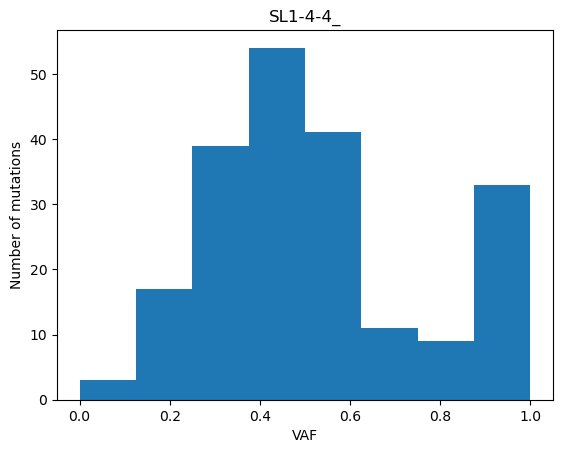

In [30]:
# Plotting
import matplotlib.pyplot as plt

# check
if sp_id == "laevis: F1":  
    branch = "SL1-4-4_"

elif sp_id == "laevis: F2":  
    branch = "SL2-4-4_"
    
elif sp_id == "leprosula: S1":
    branch = "SLE2-4-4_"

elif sp_id == "leprosula: S2":
    branch = "SLE1-4-4_"

plt.hist(
    branch_vaf_dict[branch],
    bins=8
)

plt.xlabel("VAF")
plt.ylabel("Number of mutations")
plt.title(branch)

plt.show()

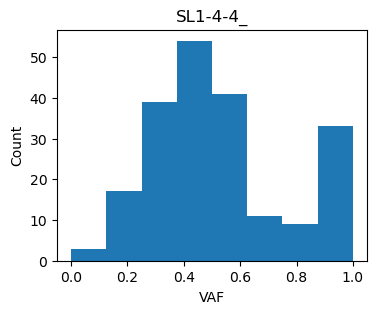

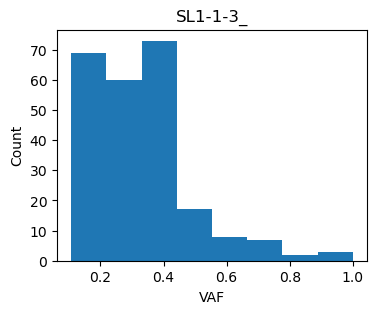

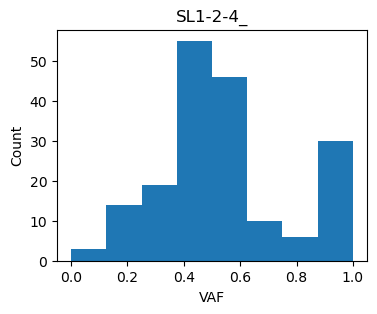

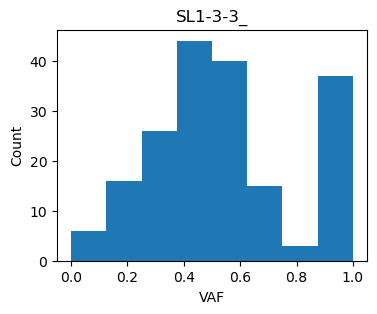

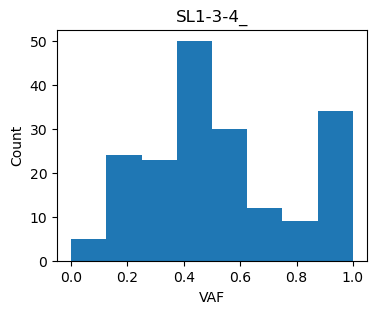

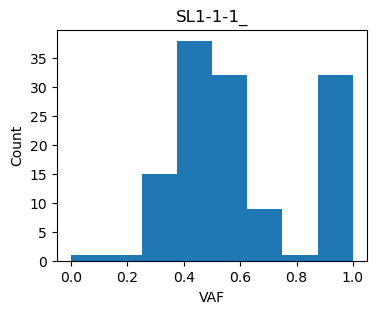

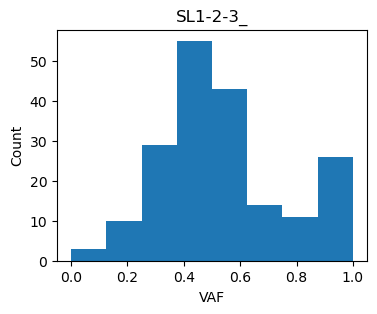

In [31]:
for branch, vafs in branch_vaf_dict.items():

    plt.figure(figsize=(4,3))
    
    plt.hist(vafs, bins=8)

    plt.title(branch)
    plt.xlabel("VAF")
    plt.ylabel("Count")

    plt.show()

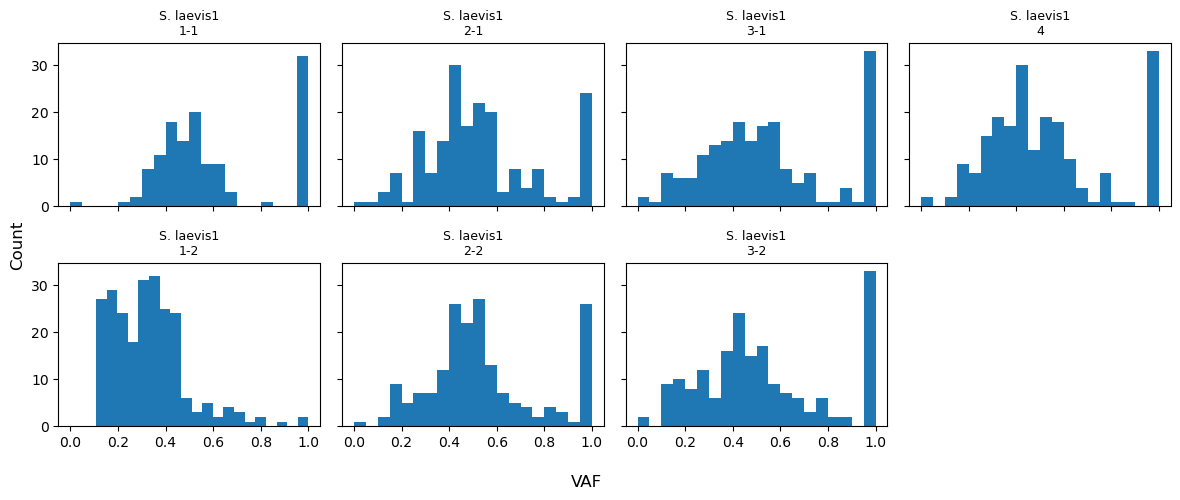

In [32]:
layout = [
    ["1-1", "2-1", "3-1", "4"],
    ["1-2", "2-2", "3-2", "0"]
]

if sp_id == "laevis: F1":
    individual = "S. laevis: F1"
elif sp_id == "laevis: F2":
    individual = "S. laevis: F2"
elif sp_id == "leprosula: S1":
    individual = "S.leprosula: S1"
elif sp_id == "leprosula: S2":
    individual = "S.leprosula: S2"
    

fig, axes = plt.subplots(
    2, 4,
    figsize=(12, 5),
    sharex=True,
    sharey=True
)

mapping = branch_maps[individual]

for row in range(2):
    for col in range(4):

        ax = axes[row, col]

        branch_id = layout[row][col]

        if branch_id is None:
            ax.axis("off")
            continue

        sample_name = mapping[branch_id]

        if sample_name not in branch_vaf_dict:
            ax.axis("off")
            continue

        ax.hist(
            branch_vaf_dict[sample_name],
            bins=20
        )

        ax.set_title(
            f"{individual[:-4]+individual[-1]}\n{branch_id}",
            fontsize=9
        )

fig.supxlabel("VAF")
fig.supylabel("Count")

plt.tight_layout()
plt.show()

### VAF average over all branches

In [33]:
all_vafs = [
    vaf
    for vafs in branch_vaf_dict.values()
    for vaf in vafs
]

In [34]:
missing = []

for _, row in mut.iterrows():

    key = (
        row["Contig or scaffold ID"],
        int(row["Position"])
    )

    if key not in vcf_dict:
        missing.append(key)

len(missing)

0

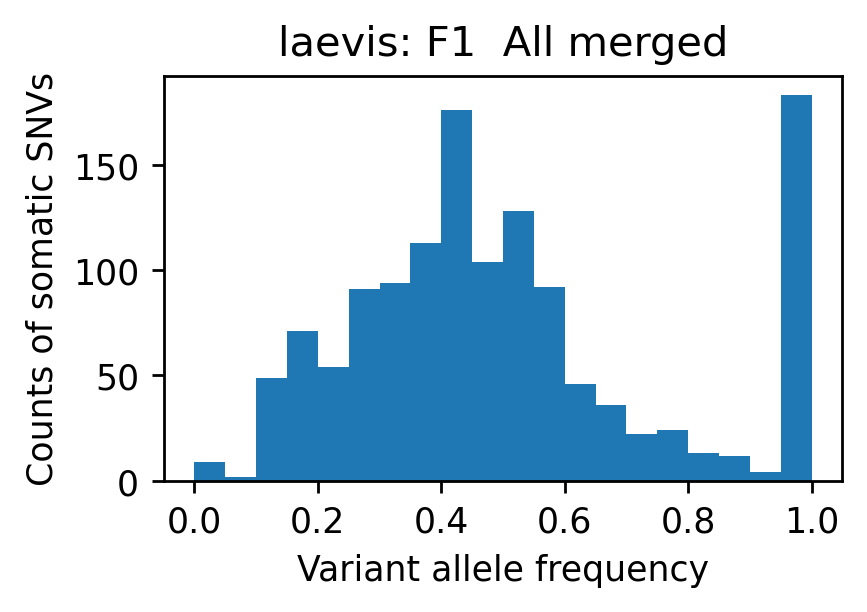

In [35]:
plt.subplots(figsize=(3.50394, 3.50394*0.6), dpi=250)

plt.hist(all_vafs, bins=20)

plt.xlabel("Variant allele frequency")
plt.ylabel("Counts of somatic SNVs")
plt.title(sp_id +"  All merged")

plt.xlim(-.05, 1.05)
plt.show()